# 11 · Position sizing: same entries, different sizes

Module **M6: position sizing and risk** (Phase 1).

**Task.** Show how **position sizing alone** changes drawdown, final equity and the probability of
ruin, holding the entry rule fixed. The entry rule is a coin flip: it has **no edge by design**.
This notebook is about risk, not returns. It is a descriptive simulation, not a strategy.

**Hypotheses (written before results).** No prior hypotheses were recorded.

**Market.** Binance **spot** BTC/USDT, daily candles, 2017-08-17 (the first Binance day) to the
last complete UTC day, 2026-11-24. Same data and cache as notebook 10.

**Questions (one row each in the Findings table at the end).**

| | Question |
|---|---|
| Q1 | Is the simulation free of look-ahead (σ30 and trades recomputed on truncated paths)? |
| Q2 | Max drawdown per scheme: median, p90, p99, and the gain needed to recover? |
| Q3 | Final equity: median, p10, p90, and % of paths that end below 10,000 USDT? |
| Q4 | P(ruin) and P(max drawdown ≥ 30%) per scheme? |
| Q5 | Do stopped trades lose what was planned (1% for the fixed-risk scheme), with 0 and 100 bps slippage? |
| Q6 | How long is the longest losing streak, compared with log2(number of trades)? |
| Q7 | How much does volatility targeting buy, and when? |
| Q8 | Does any advantage of volatility targeting over fixed risk shrink when clustering is destroyed (i.i.d. control)? |
| Q9 | Realized average exposure and number of trades per scheme. |

**Pre-specified parameters (fixed before seeing results; any later change is labelled "post-inspection").**

1. **Days as tuples.** Each day is `(open, high, low, close) / previous close`. Paths resample
   whole tuples, never separate fields.
2. **Paths.** 10,000 paths × 1,095 days (3 years), fixed seed, initial equity 10,000 USDT.
   Resampling: **(a) main** = stationary block bootstrap, mean block length 20 days;
   **(b) control** = i.i.d. day bootstrap.
3. **Return versions.** (i) **raw**; (ii) **demeaned**: the full-sample mean daily
   close-to-close return is subtracted from each day's close ratio, and open/high/low are scaled
   by the same factor. Both are reported.
4. **Common random numbers.** The same resampled paths and the same entry dates for every
   sizing scheme.
5. **Warm-up.** The first 30 days of each path only build σ30; no trades.
6. **Entry.** When flat, at each close, enter long with probability 0.20, at the next day's open.
   Long only, spot, no leverage.
7. **Exit.** Stop 5% below the entry, or a time exit at the close of day 20 after the entry,
   whichever comes first.
8. **Stop fill.** If the day opens at or below the stop → filled at the open. Otherwise, if the
   low reaches the stop → filled at stop × (1 − slippage). Slippage: **0 bps (main)** and
   **100 bps (stress)**.
9. **Costs.** 10 bps per side on notional (spot taker, notebook 07). The size is fixed at entry;
   no rebalancing during a trade.
10. **Sizing schemes.**
    1. **All-in:** notional = 100% of equity.
    2. **Fixed 1% risk:** notional = equity × 1% / 5% = 20% of equity.
    3. **Volatility targeting:** notional = equity × min(1, σ_target / σ30_t), with σ30 past-only
       and annualized with √365. σ_target = 0.20 × median(full-sample annualized σ30). This is
       a **scaling constant chosen only so that the average exposure is comparable to scheme 2**;
       it is not tuned on results.
    4. **Benchmark:** buy & hold 100%, no entries, exits or stop, on the same paths.
11. **Ruin** = equity ≤ 50% of the initial equity at any time.

**Implementation choices (made before results).**

- Day index t = 0 … 1,094 in each path. The σ30 used for an entry at the open of day t is the
  past-only σ of notebook 09: the 30 returns **before** day t. All of them are known at the close
  of day t − 1, when the coin is flipped.
- The first coin flip is at the close of day 29, so the first possible entry is the open of day
  30 (day 31 of the path). Buy & hold also buys at the open of day 30, so every scheme has the same
  1,065 days in which it can be invested.
- A position still open on the last day is sold at its close (with the fee). Buy & hold is sold the
  same way.
- "Day 20 after entry": the entry day is day 0, so the time exit is at the close of
  `entry day + 20`. The stop is checked first, also on the entry day.
- Spot, no leverage: the cash spent (notional + fee) never exceeds the equity, so "100%" means
  notional = equity / 1.001.
- Equity is marked at each daily **close**; drawdown and ruin are measured on those marks. A
  position's intraday low is not marked, so the true intraday drawdown is a bit larger.
- The resampled day after the last sample day (2026-11-24) is the first one (2017-08-18): the
  stationary bootstrap wraps around.

## 0. Setup and data

The downloader and cache are the ones from notebook 10 (`src/data/ohlcv.py`, through ccxt): if
`data/10_regimes/` already holds the file, nothing is downloaded. The returns, past-only σ and
annualization come from `src/volatility.py` (tested in 09). The new helpers are in
`src/sizing.py` (tests in `tests/test_sizing.py`).

In [1]:
%matplotlib inline
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.ohlcv import cache_path, fetch_ohlcv_window, load_or_fetch_window
from src.sizing import (EXIT_END, EXIT_STOP, EXIT_TIME, FEE_PER_SIDE, day_tuples, demean_tuples,
                        fraction_all_in, fraction_fixed_risk, fraction_vol_target,
                        iid_bootstrap_indices, longest_losing_streak, path_sigma,
                        required_recovery, simulate, simulate_buy_hold, size,
                        stationary_bootstrap_indices)
from src.volatility import DAYS_PER_YEAR, annualize, past_only_sigma, step_returns

DATA_DIR = REPO_ROOT / "data" / "10_regimes"      # reuse notebook 10's cache
START_UTC = "2017-08-01"
END_UTC = "2026-11-25"            # excluded: the last candle kept opens on 2026-11-24
NOW_UTC = "2026-11-25 00:05"      # fixed "now", so a re-run drops exactly the same candles
LABEL = "2017-08-01_2026-11-24"
DAY = pd.Timedelta(days=1)

# Pre-specified parameters (see the introduction)
SEED = 11
N_PATHS, N_DAYS = 10_000, 1_095
MEAN_BLOCK = 20
INITIAL = 10_000.0
WARMUP = 30
SIGMA_WINDOW = 30
P_ENTRY = 0.20                     # ASSUMED
STOP_PCT = 0.05                    # ASSUMED
MAX_HOLD = 20                      # ASSUMED
FEE = FEE_PER_SIDE                 # ASSUMED: 10 bps spot taker per side (notebook 07)
SLIPPAGES_BPS = [0, 100]           # ASSUMED: main and stress
RISK = 0.01
SIGMA_TARGET_SCALE = 0.20          # ASSUMED: scaling constant (exposure comparable to scheme 2)
RUIN_LEVEL = 0.50                  # ASSUMED: ruin = equity <= 50% of the initial
DD_FLAG = 0.30
EXAMPLE_PATH = 0                   # the example path is simply the first one (not picked)

SCHEME_NAMES = {"all_in": "1 all-in", "risk_1pct": "2 fixed 1% risk",
                "vol_target": "3 vol targeting", "buy_hold": "4 buy & hold"}
ACTIVE = ["all_in", "risk_1pct", "vol_target"]

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"      # categorical slots 1-3
COLOR = {"all_in": BLUE, "risk_1pct": ORANGE, "vol_target": AQUA, "buy_hold": MUTED}
STYLE = {"all_in": "-", "risk_1pct": "-", "vol_target": "-", "buy_hold": "--"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

assert abs(size(capital=10_000, risk=0.01, entry=100_000, stop=97_000) - 1 / 30) < 1e-12

In [2]:
path = cache_path(DATA_DIR, "binance", "BTC/USDT", "1d", LABEL)
candles, info = load_or_fetch_window(
    path, lambda: fetch_ohlcv_window("binance", "BTC/USDT", START_UTC, END_UTC,
                                     timeframe="1d", now_utc=NOW_UTC))
ohlc = candles[["open", "high", "low", "close"]].asfreq("D")   # regular grid (NaN if a day were missing)
close = ohlc["close"]
FIRST_DAY, LAST_DAY = close.index.min(), close.index.max()
expected = pd.date_range(FIRST_DAY, LAST_DAY, freq="D")

tuples_raw = day_tuples(ohlc)                    # one row per day after the first
o, h, l, c = (tuples_raw[k] for k in ["open", "high", "low", "close"])
pd.DataFrame([{
    "first open (UTC)": FIRST_DAY, "last open (UTC)": LAST_DAY,
    "candles": int(close.notna().sum()), "missing days": len(expected.difference(candles.index)),
    "duplicates dropped": info["duplicates_dropped"], "incomplete dropped": info["incomplete_dropped"],
    "day tuples": len(tuples_raw),
    "days with high < max(open, close)": int((h < np.maximum(o, c) - 1e-12).sum()),
    "days with low > min(open, close)": int((l > np.minimum(o, c) + 1e-12).sum()),
    "% days open = previous close exactly": round(100 * float((o == 1).mean()), 1),
    "% days |open / previous close − 1| < 0.01%": round(100 * float(((o - 1).abs() < 1e-4).mean()), 1),
    "max |open / previous close − 1| (%)": round(100 * float((o - 1).abs().max()), 2),
}]).T.rename(columns={0: "BTC/USDT 1d"})

,BTC/USDT 1d
first open (UTC),2017-08-17 00:00:00+00:00
last open (UTC),2026-11-24 00:00:00+00:00
candles,3387
missing days,0
duplicates dropped,0
incomplete dropped,0
day tuples,3386
"days with high < max(open, close)",0
"days with low > min(open, close)",0
% days open = previous close exactly,40.3


**How to read it.** The last three rows matter for the stop rule: on a 24/7 market the daily
"open" is just the first trade after 00:00 UTC, so it is (almost) the previous close. A
"gap through the stop at the open" can therefore hardly happen with daily bars, even though
price can fall through a stop in seconds within a day. Part 5 comes back to this.

### 0.1 Return versions and σ_target

The **raw** tuples keep BTC's historical drift. The **demeaned** tuples remove it, so the average
daily close-to-close return is exactly 0. A zero arithmetic mean still gives a **negative**
typical (log) growth because of volatility drag: losing 10% and then gaining 10% leaves you at
99%. That is why the demeaned buy & hold still tends to lose money.

σ_target uses the **full-sample** median of σ30. That is a constant computed with hindsight; it
is acceptable here only because its job is to make the average exposure of scheme 3 comparable
to scheme 2's, not to decide anything inside a path.

In [3]:
tuples_dm, MEAN_RET = demean_tuples(tuples_raw)
TUPLES = {"raw": tuples_raw.to_numpy(), "demeaned": tuples_dm.to_numpy()}
N_OBS = len(tuples_raw)

r = step_returns(close, DAY).reindex(close.index)
sigma_hist = annualize(past_only_sigma(r, SIGMA_WINDOW), DAYS_PER_YEAR)
SIGMA_MEDIAN = float(sigma_hist.median())
SIGMA_TARGET = SIGMA_TARGET_SCALE * SIGMA_MEDIAN
assert abs(r.mean() - MEAN_RET) < 1e-12          # same mean as the tuples' close ratios

pd.DataFrame({
    "mean daily return (bps)": {k: 1e4 * (t["close"] - 1).mean() for k, t in
                                [("raw", tuples_raw), ("demeaned", tuples_dm)]},
    "mean daily log return (bps)": {k: 1e4 * np.log(t["close"]).mean() for k, t in
                                    [("raw", tuples_raw), ("demeaned", tuples_dm)]},
    "std of daily return (%)": {k: 100 * (t["close"] - 1).std() for k, t in
                                [("raw", tuples_raw), ("demeaned", tuples_dm)]},
}).round(2).assign(**{
    "median full-sample σ30, annualized (%)": round(100 * SIGMA_MEDIAN, 1),
    "σ_target = 0.20 × median (%)": round(100 * SIGMA_TARGET, 1),
})

,mean daily return (bps),mean daily log return (bps),std of daily return (%),"median full-sample σ30, annualized (%)",σ_target = 0.20 × median (%)
raw,13.92,7.79,3.48,54.8,11.0
demeaned,0.00,-6.14,3.48,54.8,11.0


## 1. Paths and common random numbers

One random generator per job, all from one seed: one for the block bootstrap, one for the
i.i.d. bootstrap and one for the entry coin. The **same** coin draws are used for every scheme,
for both resampling methods and both return versions. Exits do not depend on the size (the stop
is 5% below the entry price, whatever the quantity), so every sizing scheme trades on exactly
the same days. The only thing that changes between schemes is how much is bought.

The check table compares the paths with the real data. The **lag-1 autocorrelation of |return|**
measures volatility clustering (a big move tends to follow a big move, notebook 09). The block
bootstrap should keep most of it (inside each block the days are in their real order). The
i.i.d. bootstrap should destroy it.

In [4]:
seeds = np.random.SeedSequence(SEED).spawn(3)
rng_block, rng_iid, rng_coin = (np.random.default_rng(s) for s in seeds)
IDX = {"block": stationary_bootstrap_indices(N_OBS, N_PATHS, N_DAYS, MEAN_BLOCK, rng_block),
       "iid": iid_bootstrap_indices(N_OBS, N_PATHS, N_DAYS, rng_iid)}
COIN = rng_coin.random((N_PATHS, N_DAYS))


def lag1_corr_rows(x):
    # Lag-1 autocorrelation of each row of x (one number per path).
    d = x - x.mean(axis=1, keepdims=True)
    return (d[:, 1:] * d[:, :-1]).sum(axis=1) / (d ** 2).sum(axis=1)


real_abs = (tuples_raw["close"] - 1).abs().to_numpy()[None, :]
rows = [{"source": "real data 2017–2026", "mean block length (days)": "—",
         "lag-1 autocorr of |return|": float(lag1_corr_rows(real_abs)[0]), "n paths": "—"}]
for res, idx in IDX.items():
    new_block = 1 + (idx[:, 1:] != (idx[:, :-1] + 1) % N_OBS).sum()
    abs_r = np.abs(TUPLES["raw"][idx, 3] - 1)
    rows.append({"source": f"{res} bootstrap (median over paths)",
                 "mean block length (days)": round(idx.size / new_block, 2),
                 "lag-1 autocorr of |return|": float(np.median(lag1_corr_rows(abs_r))),
                 "n paths": N_PATHS})
pd.DataFrame(rows).set_index("source").round(3)

,mean block length (days),lag-1 autocorr of |return|,n paths
source,,,
real data 2017–2026,—,0.179,—
block bootstrap (median over paths),20.02,0.165,10000
iid bootstrap (median over paths),1.0,-0.002,10000


**How to read it.** "Mean block length" counts how many days, on average, run in the real order
before the path jumps to a random new day (about 20 for the block bootstrap; about 1 for
i.i.d., where a run happens only by chance). A positive lag-1 autocorrelation of |return| means
calm days follow calm days and wild days follow wild days. Each path is only 3 years long, so
the path values are a little below the 9-year real value even with blocks (each path holds only
a part of the history, and the jumps between blocks break some pairs).

## 2. Look-ahead checks (Q1)

**(a) σ30 inside the paths.** For each cutoff k, σ30 is recomputed from the first k days of every
path only. Every value on days < k must be identical to the full-path value.

**(b) The whole simulation.** For the first 1,000 paths (block, raw), the simulator is run on the
first k days only. Every trade that ends before the last truncated day must be identical (same
entry day, exit day, exit type and P&L for every scheme). If any decision used a later day, some
trade would differ. The code stops (`assert`) if a check fails.

In [5]:
SCHEMES = {"all_in": fraction_all_in,
           "risk_1pct": fraction_fixed_risk(RISK, STOP_PCT),
           "vol_target": fraction_vol_target(SIGMA_TARGET)}
SIM_KW = dict(initial=INITIAL, fee=FEE, stop_pct=STOP_PCT, max_hold=MAX_HOLD, p_entry=P_ENTRY,
              warmup=WARMUP)
CUTOFFS = [60, 365, 730]

T, idx = TUPLES["raw"], IDX["block"]
sigma_full = path_sigma(T[idx, 3], SIGMA_WINDOW)
sub = slice(0, 1_000)
_, trades_full, _ = simulate(T, idx[sub], COIN[sub], sigma_full[sub], SCHEMES, **SIM_KW)
key_cols = ["path", "entry_day", "exit_day", "exit_type"] + [f"pnl_{s}" for s in ACTIVE]

rows = []
for k in CUTOFFS:
    sigma_cut = path_sigma(T[idx[:, :k], 3], SIGMA_WINDOW)
    a, b = sigma_full[:, :k], sigma_cut
    sigma_mismatch = int((~((a == b) | (np.isnan(a) & np.isnan(b)))).sum())
    _, trades_cut, _ = simulate(T, idx[sub, :k], COIN[sub, :k], sigma_cut[sub], SCHEMES, **SIM_KW)
    done_full = trades_full[trades_full["exit_day"] < k - 1][key_cols].reset_index(drop=True)
    done_cut = trades_cut[trades_cut["exit_day"] < k - 1][key_cols].reset_index(drop=True)
    same = done_full.shape == done_cut.shape and done_full.equals(done_cut)
    rows.append({"cutoff k (days)": k, "σ30 values compared": a.size,
                 "σ30 values that differ": sigma_mismatch,
                 "trades compared (1,000 paths)": len(done_full),
                 "trades that differ": 0 if same else abs(len(done_full) - len(done_cut)) or "≥1",
                 "result": "pass" if sigma_mismatch == 0 and same else "FAIL"})
    assert sigma_mismatch == 0 and same, f"look-ahead check failed at k={k}"
pd.DataFrame(rows).set_index("cutoff k (days)")

,σ30 values compared,σ30 values that differ,"trades compared (1,000 paths)",trades that differ,result
cutoff k (days),,,,,
60,600000,0,1838,0,pass
365,3650000,0,23240,0,pass
730,7300000,0,48974,0,pass


## 3. Running the simulations

2 resampling methods × 2 return versions × 2 slippage levels = 8 runs, each with the three
active schemes on the same 10,000 paths, plus buy & hold (which does not depend on slippage).
The table checks the common random numbers. Because the stop trigger does not depend on
slippage, the trade dates with 0 and 100 bps must be identical; only the fill price changes.

In [6]:
RESULTS = {}
run_rows = []
for res, idx in IDX.items():
    for ret, T in TUPLES.items():
        sig = sigma_full if (res, ret) == ("block", "raw") else path_sigma(T[idx, 3], SIGMA_WINDOW)
        bh = simulate_buy_hold(T, idx, initial=INITIAL, fee=FEE, warmup=WARMUP)
        for slip in SLIPPAGES_BPS:
            t0 = time.perf_counter()
            paths, trades, rec = simulate(T, idx, COIN, sig, SCHEMES, slippage=slip / 1e4,
                                          record_path=EXAMPLE_PATH, **SIM_KW)
            paths["buy_hold"] = bh
            trades = trades.drop(columns=["entry_px", "exit_px"]).astype(
                {c: "float32" for c in trades.columns if c.startswith(("pnl_", "frac_"))})
            RESULTS[(res, ret, slip)] = {"paths": paths, "trades": trades, "rec": rec}
            run_rows.append({"resampling": res, "returns": ret, "slippage (bps)": slip,
                             "trades": len(trades),
                             "mean trades per path": trades.groupby("path").size().mean(),
                             "seconds": time.perf_counter() - t0})
        if (res, ret) == ("block", "raw"):
            SIGMA_EXAMPLE = sig[EXAMPLE_PATH].copy()
        a = RESULTS[(res, ret, 0)]["trades"][["path", "entry_day", "exit_day", "exit_type"]]
        b = RESULTS[(res, ret, 100)]["trades"][["path", "entry_day", "exit_day", "exit_type"]]
        assert a.equals(b), "trade dates should not depend on slippage"
        del sig
del sigma_full
pd.DataFrame(run_rows).set_index(["resampling", "returns", "slippage (bps)"]).round(1)

trades  mean trades per path  seconds
resampling returns  slippage (bps)                                       
block      raw      0               752740                  75.3      3.5
                    100             752740                  75.3      3.8
           demeaned 0               788927                  78.9      5.6
                    100             788927                  78.9      4.6
iid        raw      0               788094                  78.8      3.5
                    100             788094                  78.8      5.6
           demeaned 0               825035                  82.5      4.1
                    100             825035                  82.5      3.7

## 4. Drawdown, final equity and ruin (Q2–Q4)

Helper: one row per (resampling, return version, scheme), slippage 0 bps. All percentages are of
equity. "Required recovery" is the gain needed to get back to the peak after a drawdown L:
L / (1 − L). A 50% fall needs +100%.

In [7]:
def pct(x):
    return 100 * x


def scheme_rows(slip=0):
    rows = []
    for (res, ret, s), out in RESULTS.items():
        if s != slip:
            continue
        for scheme, p in out["paths"].items():
            dd, fe = p["max_dd"], p["final_equity"]
            rows.append({
                "resampling": res, "returns": ret, "scheme": SCHEME_NAMES[scheme],
                "max DD median (%)": pct(dd.median()), "max DD p90 (%)": pct(dd.quantile(0.9)),
                "max DD p99 (%)": pct(dd.quantile(0.99)),
                "recovery needed, median DD (%)": pct(required_recovery(dd.median())),
                "recovery needed, p90 DD (%)": pct(required_recovery(dd.quantile(0.9))),
                "final equity median": fe.median(), "final equity p10": fe.quantile(0.1),
                "final equity p90": fe.quantile(0.9),
                "% paths below 10,000": pct((fe < INITIAL).mean()),
                "P(ruin) (%)": pct((p["min_equity"] <= RUIN_LEVEL * INITIAL).mean()),
                "P(max DD ≥ 30%) (%)": pct((dd >= DD_FLAG).mean()),
                "mean exposure (%)": pct(p["mean_exposure"].mean()),
                "mean trades per path": p["n_trades"].mean(),
            })
    return pd.DataFrame(rows).set_index(["resampling", "returns", "scheme"])   # run order


TABLE = scheme_rows(0)
TABLE.iloc[:, :5].round(1)

max DD median (%)  max DD p90 (%)  max DD p99 (%)  recovery needed, median DD (%)  recovery needed, p90 DD (%)
resampling returns  scheme                                                                                                                         
block      raw      1 all-in                      60.0            79.7            89.7                           150.0                        393.3
                    2 fixed 1% risk               16.1            26.0            35.0                            19.1                         35.1
                    3 vol targeting               15.7            24.8            34.4                            18.6                         33.1
                    4 buy & hold                  65.4            84.3            93.5                           189.0                        535.7
           demeaned 1 all-in                      72.7            88.6            94.7                           266.7                        779.7
                    2 fixed 1% risk               21.4            33.6            42.9                            27.3                         50.5
                    3 vol targeting               21.2            33.2            42.8                            26.9                         49.7
                    4 buy & hold                  80.8            94.1            98.0                           421.6                       1606.6
iid        raw      1 all-in                      63.7            82.1            91.7                           175.2                        457.7
                    2 fixed 1% risk               17.2            27.3            37.5                            20.8                         37.6
                    3 vol targeting               15.9            25.3            34.7                            18.9                         33.9
                    4 buy & hold                  63.4            82.1            92.6                           173.4                        457.7
           demeaned 1 all-in                      77.1            90.6            95.7                           337.2                        960.4
                    2 fixed 1% risk               23.5            35.6            45.2                            30.7                         55.4
                    3 vol targeting               21.6            33.1            42.3                            27.5                         49.5
                    4 buy & hold                  79.2            93.2            97.5                           380.6                       1374.0

**How to read it.** Each row is a distribution over 10,000 paths summarized by three numbers:
the median path, the worst 10% (p90) and the worst 1% (p99) of maximum drawdowns. The last two
columns turn the drawdown into the gain needed to come back. The shared entry dates mean that the
difference between rows of the same block is **only** the size.

In [8]:
TABLE.iloc[:, 5:9].round(1)

final equity median  final equity p10  final equity p90  % paths below 10,000
resampling returns  scheme                                                                                        
block      raw      1 all-in                     14157.2            3961.7           52024.5                  36.3
                    2 fixed 1% risk              11550.4            8795.5           15469.6                  25.2
                    3 vol targeting              11698.7            8885.3           15735.7                  23.7
                    4 buy & hold                 22672.4            4491.0          114687.0                  26.3
           demeaned 1 all-in                      5633.6            1666.4           20202.1                  71.9
                    2 fixed 1% risk               9489.3            7314.9           12610.6                  59.3
                    3 vol targeting               9593.7            7346.1           12799.9                  57.9
                    4 buy & hold                  5152.7            1018.6           26122.9                  70.0
iid        raw      1 all-in                     10409.7            3183.2           34740.5                  48.1
                    2 fixed 1% risk              10836.1            8423.3           14073.6                  34.5
                    3 vol targeting              10739.4            8537.7           13690.8                  35.0
                    4 buy & hold                 23069.8            5180.3           98276.2                  23.3
           demeaned 1 all-in                      4136.8            1328.9           13079.9                  83.8
                    2 fixed 1% risk               8900.7            6995.1           11383.8                  72.7
                    3 vol targeting               9018.4            7230.1           11343.8                  72.2
                    4 buy & hold                  5244.0            1175.0           22382.5                  71.5

**How to read it.** Final equity after 3 years, in USDT, starting from 10,000. p10 is the path
that only 10% of paths do worse than; p90 the path that only 10% beat. "% paths below 10,000" is
the share of paths that lose money. With **raw** returns every scheme inherits BTC's
2017–2026 drift; with **demeaned** returns the drift is gone, so whatever remains is volatility
drag plus costs.

In [9]:
TABLE.iloc[:, 9:11].round(2)

P(ruin) (%)  P(max DD ≥ 30%) (%)
resampling returns  scheme                                           
block      raw      1 all-in               33.23                99.61
                    2 fixed 1% risk         0.00                 4.01
                    3 vol targeting         0.00                 3.19
                    4 buy & hold           35.36                99.88
           demeaned 1 all-in               64.88                99.95
                    2 fixed 1% risk         0.03                18.29
                    3 vol targeting         0.02                17.06
                    4 buy & hold           72.25               100.00
iid        raw      1 all-in               42.51                99.88
                    2 fixed 1% risk         0.02                 5.67
                    3 vol targeting         0.00                 3.74
                    4 buy & hold           30.34                99.97
           demeaned 1 all-in               76.12               100.00
                    2 fixed 1% risk         0.12                24.88
                    3 vol targeting         0.02                17.85
                    4 buy & hold           70.91               100.00

**How to read it.** P(ruin) is the share of paths whose equity closed at or below 5,000 USDT on
some day. P(max DD ≥ 30%) is the share of paths with a fall of 30% or more from their peak.
With 10,000 paths, the standard error of a share is at most about half a percentage point
(√(0.25 / 10,000)).

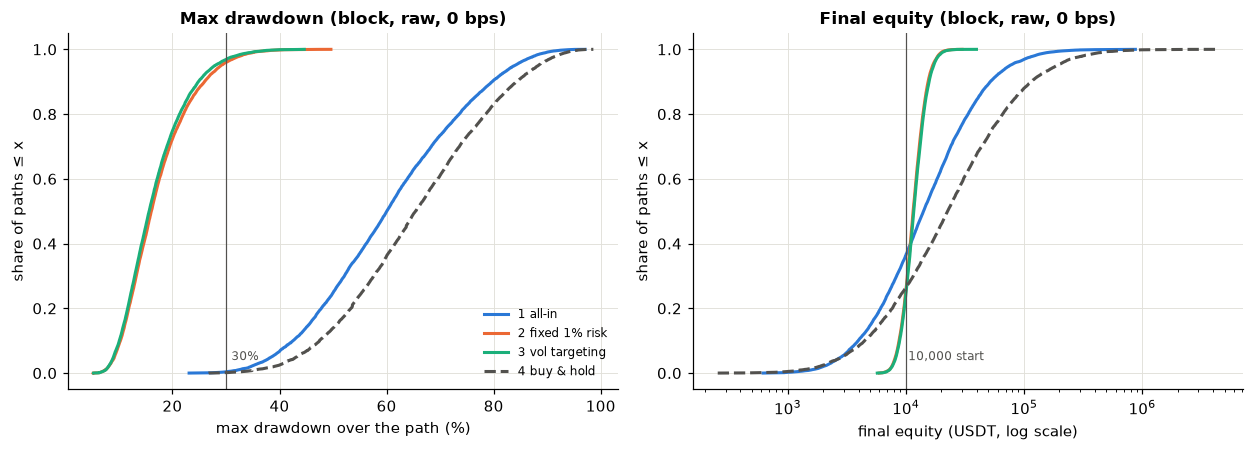

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
paths_br = RESULTS[("block", "raw", 0)]["paths"]
for scheme, p in paths_br.items():
    for ax, col, scale in [(axes[0], "max_dd", 100), (axes[1], "final_equity", 1)]:
        x = np.sort(p[col].to_numpy() * scale)
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=COLOR[scheme], ls=STYLE[scheme],
                lw=2, label=SCHEME_NAMES[scheme])
axes[0].axvline(100 * DD_FLAG, color=MUTED, lw=0.8)
axes[0].text(100 * DD_FLAG + 1, 0.04, "30%", color=MUTED, fontsize=8)
axes[0].set(xlabel="max drawdown over the path (%)", ylabel="share of paths ≤ x",
            title="Max drawdown (block, raw, 0 bps)")
axes[1].axvline(INITIAL, color=MUTED, lw=0.8)
axes[1].text(INITIAL * 1.05, 0.04, "10,000 start", color=MUTED, fontsize=8)
axes[1].set_xscale("log")
axes[1].set(xlabel="final equity (USDT, log scale)", ylabel="share of paths ≤ x",
            title="Final equity (block, raw, 0 bps)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

**How to read it.** Both panels are cumulative distributions (ECDFs): for any x on the
horizontal axis, the height of a line is the share of paths with a value ≤ x. A line further to
the **left** in the left panel means smaller drawdowns. In the right panel, a **steep** line means
outcomes bunched together, and a flat, wide line means a wide spread of outcomes. The tables above
are the same distributions read at the 50%, 90% and 99% heights.

## 5. Stopped trades: planned vs realized loss (Q5)

**Planned loss** = fraction of equity bought × 5% (the stop distance). For scheme 2 that is
always 1%. **Realized loss** = the fall in equity from just before the entry to just after the
exit, as a % of that equity, so it includes both fees and any slippage or gap. A "gap fill" is a
stop filled at an open that was already at or below the stop.

**What daily bars cannot see.** The simulator only knows each day's open, high, low and close.
When the low is below the stop, it assumes the stop was filled at the stop price (minus
slippage). In a real crash, the price can jump through the stop within seconds and the order
fills far lower (notebooks 04 and 07). Nothing in daily bars can show this, so the realized
losses here are a **lower bound** on real ones. The 100 bps version is a crude stress for it.

In [11]:
rows = []
for slip in SLIPPAGES_BPS:
    tr = RESULTS[("block", "raw", slip)]["trades"]
    stops = tr[tr["exit_type"] == EXIT_STOP]
    for scheme in ACTIVE:
        planned = stops[f"frac_{scheme}"].astype(float) * STOP_PCT
        realized = -stops[f"pnl_{scheme}"].astype(float)
        ratio = realized / planned
        rows.append({"slippage (bps)": slip, "scheme": SCHEME_NAMES[scheme],
                     "stopped trades": len(stops), "of which gap fills": int(stops["gap_open"].sum()),
                     "planned loss median (% equity)": pct(planned.median()),
                     "realized median (% equity)": pct(realized.median()),
                     "realized p99": pct(realized.quantile(0.99)), "realized max": pct(realized.max()),
                     "realized / planned, median": ratio.median(),
                     "realized / planned, max": ratio.max(),
                     "% stops > 1.5× planned": pct((ratio > 1.5).mean())})
STOPS = pd.DataFrame(rows).set_index(["slippage (bps)", "scheme"])
STOPS.round(3)

stopped trades  of which gap fills  planned loss median (% equity)  realized median (% equity)  realized p99  realized max  \
slippage (bps) scheme                                                                                                                                        
0              1 all-in                 522111                   2                           4.995                       5.190         5.190         5.451   
               2 fixed 1% risk          522111                   2                           1.000                       1.039         1.039         1.091   
               3 vol targeting          522111                   2                           0.886                       0.921         2.164         4.112   
100            1 all-in                 522111                   2                           4.995                       6.138         6.138         6.138   
               2 fixed 1% risk          522111                   2                           1.000                       1.229         1.229         1.229   
               3 vol targeting          522111                   2                           0.886                       1.089         2.559         4.863   

                                realized / planned, median  realized / planned, max  % stops > 1.5× planned  
slippage (bps) scheme                                                                                        
0              1 all-in                              1.039                    1.091                     0.0  
               2 fixed 1% risk                       1.039                    1.091                     0.0  
               3 vol targeting                       1.039                    1.091                     0.0  
100            1 all-in                              1.229                    1.229                     0.0  
               2 fixed 1% risk                       1.229                    1.229                     0.0  
               3 vol targeting                       1.229                    1.229                     0.0

**How to read it.** One row per slippage level and scheme, for the block / raw paths (the stop
fills depend only on the day tuples, so the other versions look the same). The ratio columns
compare each trade with its own plan. Since a fill below the stop is only possible through a
gap at the open, and opens equal the previous close on most days, the ratio can barely move
above what fees and the assumed slippage add.

In [12]:
rows = []
for slip in SLIPPAGES_BPS:
    p = RESULTS[("block", "raw", slip)]["paths"]
    for scheme in ACTIVE:
        rows.append({"scheme": SCHEME_NAMES[scheme], "slippage (bps)": slip,
                     "max DD median (%)": pct(p[scheme]["max_dd"].median()),
                     "max DD p99 (%)": pct(p[scheme]["max_dd"].quantile(0.99)),
                     "final equity median": p[scheme]["final_equity"].median(),
                     "P(ruin) (%)": pct((p[scheme]["min_equity"] <= RUIN_LEVEL * INITIAL).mean())})
pd.DataFrame(rows).set_index(["scheme", "slippage (bps)"]).round(1)

,,max DD median (%),max DD p99 (%),final equity median,P(ruin) (%)
scheme,slippage (bps),,,,
1 all-in,0,60.0,89.7,14157.2,33.2
2 fixed 1% risk,0,16.1,35.0,11550.4,0.0
3 vol targeting,0,15.7,34.4,11698.7,0.0
1 all-in,100,69.5,94.5,8441.2,53.6
2 fixed 1% risk,100,19.9,41.9,10464.0,0.0
3 vol targeting,100,19.3,41.3,10641.7,0.0


**How to read it.** The same paths and trades, with the stress slippage on every stop fill.
The extra 1% of the fill price costs each stopped trade 1% × the fraction bought, and most trades
end on the stop, so the gap between the 0 and 100 bps rows grows with the size of each trade.

## 6. Losing streaks (Q6)

A losing trade is one with a negative net P&L. The sign does not depend on the size, so the
streaks are the same for every active scheme. The reference **log2(n)** is the length of the
longest run of heads you would typically see in n tosses of a fair coin. Here a loss is more
likely than a win (a 5% stop is hit before a 20-day exit most of the time), so a second
reference uses the measured loss rate p: about log_{1/p}(n·(1 − p)). What a streak costs depends
on the size: k losses in a row at about 1.04% each (scheme 2) is a fall of 1 − (1 − 0.0104)^k.

In [13]:
rows, STREAK = [], {}
for res in IDX:
    out = RESULTS[(res, "raw", 0)]
    tr, p = out["trades"], out["paths"]["risk_1pct"]
    streak = longest_losing_streak(tr, N_PATHS, "pnl_risk_1pct")
    n = p["n_trades"].to_numpy()
    loss_rate = float((tr["pnl_risk_1pct"] < 0).mean())
    log2n = np.log2(np.maximum(n, 1))
    ref_p = np.log(np.maximum(n, 1) * (1 - loss_rate)) / np.log(1 / loss_rate)
    STREAK[res] = streak
    loss_k = -tr.loc[tr["exit_type"] == EXIT_STOP, "pnl_risk_1pct"].median()
    rows.append({"resampling": res, "loss rate p (%)": pct(loss_rate),
                 "longest streak median": streak.median(), "p90": streak.quantile(0.9),
                 "p99": streak.quantile(0.99), "max": streak.max(),
                 "log2(n trades) median": np.median(log2n),
                 "log_(1/p)(n(1−p)) median": np.median(ref_p),
                 "% paths streak > log2(n)": pct((streak > log2n).mean()),
                 "fall from median streak, scheme 2 (%)": pct(1 - (1 - loss_k) ** streak.median()),
                 "fall from median streak, all-in (%)": pct(1 - (1 - 5 * loss_k) ** streak.median())})
pd.DataFrame(rows).set_index("resampling").round(2)

,loss rate p (%),longest streak median,p90,p99,max,log2(n trades) median,log_(1/p)(n(1−p)) median,% paths streak > log2(n),"fall from median streak, scheme 2 (%)","fall from median streak, all-in (%)"
resampling,,,,,,,,,,
block,72.01,11.0,17.0,24.0,44,6.23,9.27,94.53,10.85,44.39
iid,75.03,11.0,18.0,26.0,50,6.30,10.38,96.72,10.85,44.39


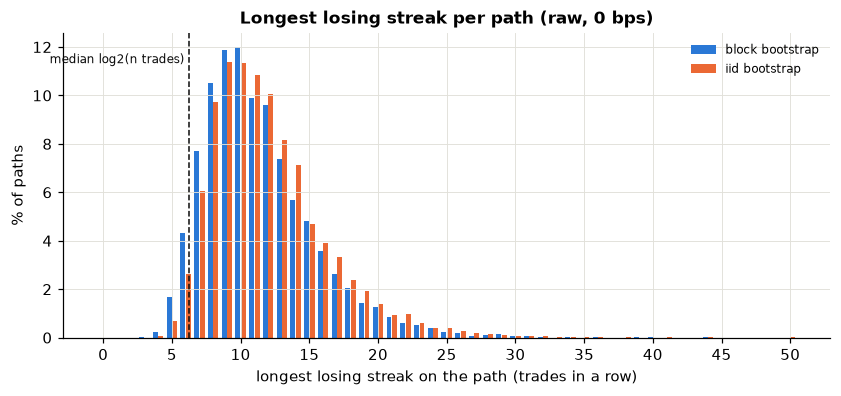

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
k_max = int(max(s.max() for s in STREAK.values()))
bins = np.arange(0, k_max + 1)
width = 0.4
for i, (res, s) in enumerate(STREAK.items()):
    share = s.value_counts(normalize=True).reindex(bins, fill_value=0)
    ax.bar(bins + (i - 0.5) * width, 100 * share, width=width - 0.04,
           color=[BLUE, ORANGE][i], label=f"{res} bootstrap")
log2_med = np.median(np.log2(RESULTS[("block", "raw", 0)]["paths"]["risk_1pct"]["n_trades"]))
ax.axvline(log2_med, color=INK, lw=1, ls="--")
ax.text(log2_med - 0.3, ax.get_ylim()[1] * 0.9, "median log2(n trades)", fontsize=8, color=INK,
        ha="right")
ax.set(xlabel="longest losing streak on the path (trades in a row)", ylabel="% of paths",
       title="Longest losing streak per path (raw, 0 bps)", xticks=bins[::5])
ax.legend(frameon=False, fontsize=8)
plt.show()

**How to read it.** Each bar is the share of the 10,000 paths whose longest losing streak was k
trades. Blue = block bootstrap, orange = i.i.d. control. The dashed line is the median
log2(number of trades). The bars sit to the right of it because a loss is more likely than a win
here, so long runs of losses are more common than for a fair coin.

## 7. What volatility targeting buys (Q7)

Scheme 3 buys `min(1, σ_target / σ30)` of equity. When recent volatility is at its full-sample
median it buys 20%, the same as scheme 2. When σ30 is high it buys less, and when σ30 is low it
buys more, up to 100%. The table is over all trades on the block / raw paths.

In [15]:
tr = RESULTS[("block", "raw", 0)]["trades"]
f3 = tr["frac_vol_target"].astype(float)
q = f3.quantile([0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
pd.DataFrame([{
    "trades": len(f3), "mean fraction (%)": pct(f3.mean()),
    **{f"p{int(100 * k)} (%)": pct(v) for k, v in q.items()},
    "% trades at the 100% cap": pct((f3 >= 1 / (1 + FEE) - 1e-9).mean()),
    "% trades above 20%": pct((f3 > 0.2).mean()),
    "fixed 1% risk, every trade (%)": pct(tr["frac_risk_1pct"].astype(float).mean()),
}]).T.rename(columns={0: "vol targeting (block, raw)"}).round(2)

,"vol targeting (block, raw)"
trades,752740.00
mean fraction (%),19.32
p1 (%),6.81
p10 (%),11.06
p25 (%),14.04
p50 (%),18.17
p75 (%),23.23
p90 (%),29.05
p99 (%),42.20
% trades at the 100% cap,0.00


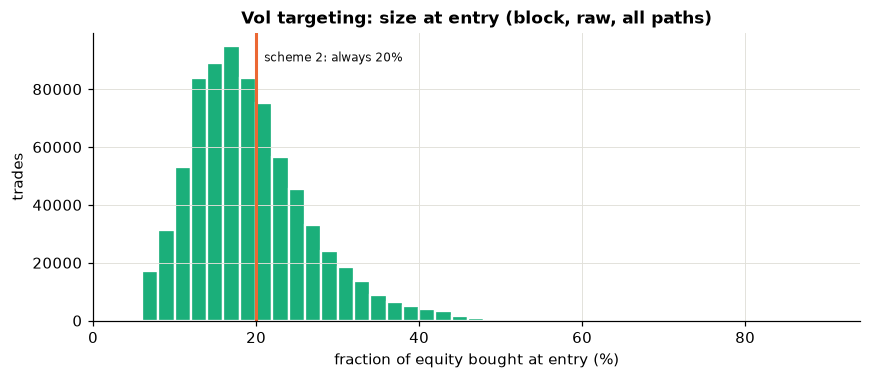

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(100 * f3, bins=np.arange(0, 101, 2), color=AQUA, edgecolor="white", linewidth=1.5)
ax.set_xlim(0, max(60, 100 * f3.max() + 4))      # nothing near the 100% cap
ax.axvline(100 * RISK / STOP_PCT, color=ORANGE, lw=2)
ax.text(100 * RISK / STOP_PCT + 1, ax.get_ylim()[1] * 0.9, "scheme 2: always 20%", fontsize=8,
        color=INK)
ax.set(xlabel="fraction of equity bought at entry (%)", ylabel="trades",
       title="Vol targeting: size at entry (block, raw, all paths)")
plt.show()

**How to read it.** Each bar counts trades (over all 10,000 paths) by the fraction of equity
scheme 3 bought. The orange line is scheme 2, which always buys 20%. A trade would be capped at 100% only if σ30 fell
below σ_target itself; the table shows how often that happened. The shape mirrors the
distribution of σ30 in the resampled days: σ_target / σ is large when σ is small, so the long
tail is on the right.

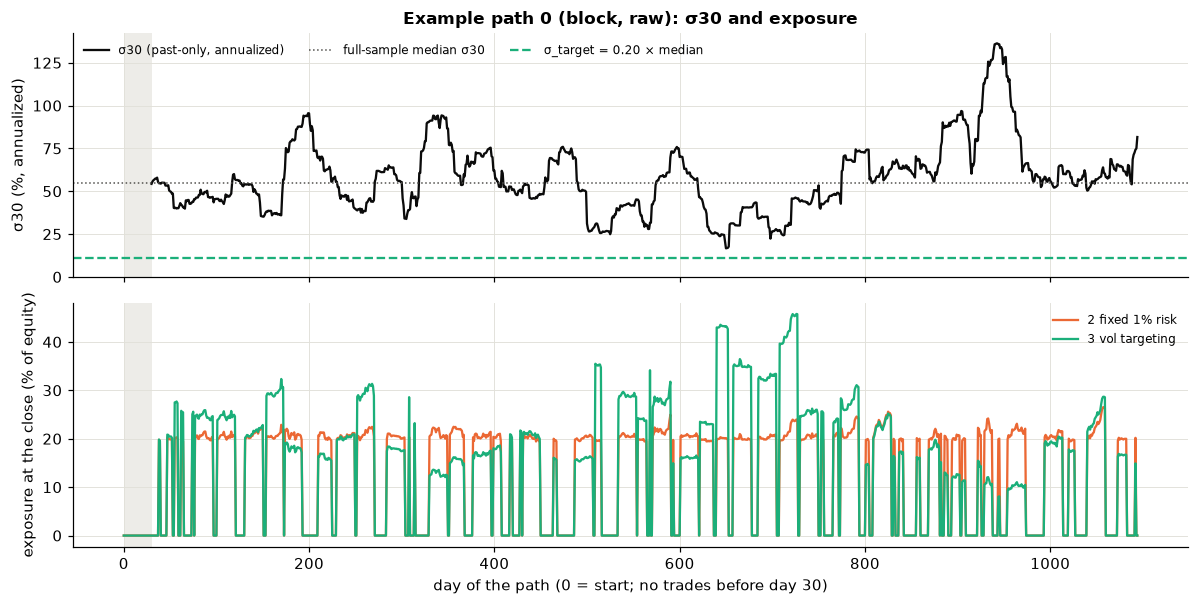

In [17]:
rec = RESULTS[("block", "raw", 0)]["rec"]
days = np.arange(N_DAYS)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
ax1.plot(days, 100 * SIGMA_EXAMPLE, color=INK, lw=1.5, label="σ30 (past-only, annualized)")
ax1.axhline(100 * SIGMA_MEDIAN, color=MUTED, lw=1, ls=":", label="full-sample median σ30")
ax1.axhline(100 * SIGMA_TARGET, color=AQUA, lw=1.5, ls="--", label="σ_target = 0.20 × median")
ax1.set_ylim(0, None)
ax1.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
ax1.set(ylabel="σ30 (%, annualized)", title=f"Example path {EXAMPLE_PATH} (block, raw): σ30 and exposure")
for scheme in ["risk_1pct", "vol_target"]:
    ax2.plot(days, 100 * rec["exposure"][ACTIVE.index(scheme)], color=COLOR[scheme], lw=1.5,
             label=SCHEME_NAMES[scheme])
ax2.set(xlabel="day of the path (0 = start; no trades before day 30)",
        ylabel="exposure at the close (% of equity)")
ax2.legend(frameon=False, fontsize=8, loc="upper right")
for ax in (ax1, ax2):
    ax.axvspan(0, WARMUP, color=GRID, alpha=0.6, lw=0)
fig.tight_layout()
plt.show()

**How to read it.** Top: σ30 along one simulated path (the first one, not picked). Bottom: the
value of the position divided by equity at each close, for scheme 2 (orange) and scheme 3
(aqua); zero means flat. Both schemes are in and out on the same days (same coin flips, same
exits). Only the height differs: scheme 3 is tall where σ30 is low and short where it is high.
Inside a trade, exposure drifts a bit with the price because the size is fixed at entry and
nothing is rebalanced. The grey band is the warm-up.

## 8. Block vs i.i.d.: does the advantage of volatility targeting shrink? (Q8)

Volatility targeting can only help if **today's σ30 says something about the next days'**
volatility. That is what clustering means. The i.i.d. control destroys clustering: σ30 still
moves, but it no longer predicts the next 20 days. If scheme 3's advantage over scheme 2 comes
from clustering, it should shrink under i.i.d.

Each number is scheme 3 minus scheme 2 on the same paths (negative = scheme 3 has smaller
drawdowns). The paired mean difference comes with a 95% interval (±1.96 standard errors of the
10,000 paired differences).

In [18]:
rows = []
for ret in TUPLES:
    for res in IDX:
        p = RESULTS[(res, ret, 0)]["paths"]
        a, b = p["vol_target"], p["risk_1pct"]
        d = a["max_dd"] - b["max_dd"]
        se = d.std(ddof=1) / math.sqrt(len(d))
        rows.append({"returns": ret, "resampling": res,
                     "Δ max DD median (pp)": pct(a["max_dd"].median() - b["max_dd"].median()),
                     "Δ max DD p90 (pp)": pct(a["max_dd"].quantile(0.9) - b["max_dd"].quantile(0.9)),
                     "Δ max DD p99 (pp)": pct(a["max_dd"].quantile(0.99) - b["max_dd"].quantile(0.99)),
                     "paired mean Δ max DD (pp)": pct(d.mean()),
                     "95% interval (pp)": f"{pct(d.mean() - 1.96 * se):.2f} to {pct(d.mean() + 1.96 * se):.2f}",
                     "% paths with smaller DD under scheme 3": pct((d < 0).mean()),
                     "Δ final equity median (USDT)": a["final_equity"].median() - b["final_equity"].median(),
                     "Δ mean exposure (pp)": pct(a["mean_exposure"].mean() - b["mean_exposure"].mean())})
Q8 = pd.DataFrame(rows).set_index(["returns", "resampling"])
Q8.round(2)

Δ max DD median (pp)  Δ max DD p90 (pp)  Δ max DD p99 (pp)  paired mean Δ max DD (pp) 95% interval (pp)  \
returns  resampling                                                                                                            
raw      block                      -0.41              -1.14              -0.53                      -0.47    -0.53 to -0.41   
         iid                        -1.30              -2.00              -2.77                      -1.35    -1.39 to -1.31   
demeaned block                      -0.25              -0.36              -0.09                      -0.33    -0.39 to -0.26   
         iid                        -1.92              -2.51              -2.97                      -1.82    -1.86 to -1.77   

                     % paths with smaller DD under scheme 3  Δ final equity median (USDT)  Δ mean exposure (pp)  
returns  resampling                                                                                              
raw      block                                        55.66                        148.40                  0.17  
         iid                                          77.39                        -96.77                 -1.39  
demeaned block                                        52.84                        104.42                  0.22  
         iid                                          80.12                        117.69                 -1.32

**How to read it.** Compare the **block** and **iid** rows within each return version. "pp" are
percentage points of drawdown (a change from 16% to 15% is −1 pp). The last column checks that
the two schemes are compared at a similar average exposure: if scheme 3 were simply smaller on
average, it would also have smaller drawdowns, with no help from clustering.

### 8.1 Exposure-matched comparison (post-inspection)

**Why this was added after seeing the table above.** Under i.i.d. resampling, scheme 3 also
holds less BTC on average than scheme 2 (last column), so part of its smaller drawdown is simply
a smaller position. The reason: σ_target was set from the median of the **real**, clustered σ30.
Without clustering, every 30-day window mixes calm and wild days, so σ30 on an i.i.d. path sits
close to the overall σ of the sample, above that median. Scheme 3 then buys less than 20% on most
trades.

**Check.** For each case, σ_target is rescaled so that scheme 3's mean time-weighted exposure
equals scheme 2's: σ_target × exposure₂ / exposure₃. The 100% cap never binds (Part 7), so
exposure is close to proportional to σ_target. Only scheme 3 is re-run, on the same paths, coin
flips and exits. The pre-specified result above is kept as it is; this table is a sensitivity
check, not a replacement.

In [19]:
rows = []
for ret, T in TUPLES.items():
    for res, idx in IDX.items():
        p = RESULTS[(res, ret, 0)]["paths"]
        e2, e3 = p["risk_1pct"]["mean_exposure"].mean(), p["vol_target"]["mean_exposure"].mean()
        target = SIGMA_TARGET * e2 / e3
        sig = path_sigma(T[idx, 3], SIGMA_WINDOW)
        assert np.nanmin(sig[:, WARMUP:]) > target, "the 100% cap would bind"
        m, _, _ = simulate(T, idx, COIN, sig, {"vol_target": fraction_vol_target(target)},
                           slippage=0.0, **SIM_KW)
        a, b = m["vol_target"], p["risk_1pct"]
        d = a["max_dd"] - b["max_dd"]
        se = d.std(ddof=1) / math.sqrt(len(d))
        rows.append({"returns": ret, "resampling": res,
                     "median σ30 on paths (%)": pct(np.nanmedian(sig[:, WARMUP:])),
                     "rescaled σ_target (%)": pct(target),
                     "exposure scheme 2 (%)": pct(e2),
                     "exposure scheme 3, matched (%)": pct(a["mean_exposure"].mean()),
                     "Δ max DD median (pp)": pct(a["max_dd"].median() - b["max_dd"].median()),
                     "Δ max DD p90 (pp)": pct(a["max_dd"].quantile(0.9) - b["max_dd"].quantile(0.9)),
                     "paired mean Δ max DD (pp)": pct(d.mean()),
                     "95% interval (pp)": f"{pct(d.mean() - 1.96 * se):.2f} to {pct(d.mean() + 1.96 * se):.2f}",
                     "% paths with smaller DD under scheme 3": pct((d < 0).mean())})
        del sig
Q8M = pd.DataFrame(rows).set_index(["returns", "resampling"])
Q8M.round(2)

median σ30 on paths (%)  rescaled σ_target (%)  exposure scheme 2 (%)  exposure scheme 3, matched (%)  Δ max DD median (pp)  \
returns  resampling                                                                                                                                
raw      block                          57.2                  10.83                  13.64                           13.64                 -0.58   
         iid                            62.5                  12.24                  13.35                           13.33                  0.40   
demeaned block                          57.2                  10.79                  13.21                           13.21                 -0.56   
         iid                            62.5                  12.21                  12.91                           12.89                  0.27   

                     Δ max DD p90 (pp)  paired mean Δ max DD (pp) 95% interval (pp)  % paths with smaller DD under scheme 3  
returns  resampling                                                                                                          
raw      block                   -1.40                      -0.65    -0.71 to -0.60                                   58.39  
         iid                      0.55                       0.42      0.38 to 0.46                                   41.71  
demeaned block                   -0.80                      -0.64    -0.71 to -0.57                                   56.76  
         iid                      0.54                       0.40      0.35 to 0.44                                   42.91

**How to read it.** Same layout as the table above, but now both schemes hold about the same
amount of BTC on average (third and fourth columns). Any drawdown difference left comes from
**when** scheme 3 is big or small, which is the part that depends on clustering. Compare block
with iid inside each return version.

## 9. Realized exposure and number of trades (Q9)

**Time-weighted exposure** = position value / equity at each close, averaged over the 1,065
days after the warm-up (flat days count as 0). **Exposure while in a trade** = the average
fraction of equity bought at entry. Trades and time in market are the same for every active
scheme (common random numbers).

In [20]:
rows = []
for res in IDX:
    out = RESULTS[(res, "raw", 0)]
    tr = out["trades"]
    in_market = (tr["exit_day"] - tr["entry_day"] + 1).groupby(tr["path"]).sum().reindex(
        range(N_PATHS), fill_value=0) / (N_DAYS - WARMUP)
    for scheme, p in out["paths"].items():
        rows.append({"resampling": res, "scheme": SCHEME_NAMES[scheme],
                     "time-weighted exposure, mean (%)": pct(p["mean_exposure"].mean()),
                     "time-weighted exposure, median (%)": pct(p["mean_exposure"].median()),
                     "exposure while in a trade (%)": (pct(tr[f"frac_{scheme}"].astype(float).mean())
                                                       if scheme in ACTIVE else 100 / (1 + FEE)),
                     "trades per path, mean": p["n_trades"].mean(),
                     "trades per path, median": p["n_trades"].median(),
                     "% days in market": (pct(in_market.mean()) if scheme in ACTIVE else 100.0)})
EXPO = pd.DataFrame(rows).set_index(["resampling", "scheme"])
exit_mix = (RESULTS[("block", "raw", 0)]["trades"]["exit_type"].value_counts(normalize=True) * 100)
display(EXPO.round(2))
exit_mix.round(1).rename("% of trades (block, raw)").to_frame()

time-weighted exposure, mean (%)  time-weighted exposure, median (%)  exposure while in a trade (%)  trades per path, mean  \
resampling scheme                                                                                                                                        
block      1 all-in                                    64.64                               64.69                          99.90                  75.27   
           2 fixed 1% risk                             13.64                               13.66                          20.00                  75.27   
           3 vol targeting                             13.81                               13.76                          19.32                  75.27   
           4 buy & hold                               100.00                              100.00                          99.90                   1.00   
iid        1 all-in                                    62.96                               63.00                          99.90                  78.81   
           2 fixed 1% risk                             13.35                               13.37                          20.00                  78.81   
           3 vol targeting                             11.96                               11.95                          17.90                  78.81   
           4 buy & hold                               100.00                              100.00                          99.90                   1.00   

                            trades per path, median  % days in market  
resampling scheme                                                      
block      1 all-in                            75.0             71.71  
           2 fixed 1% risk                     75.0             71.71  
           3 vol targeting                     75.0             71.71  
           4 buy & hold                         1.0            100.00  
iid        1 all-in                            79.0             70.36  
           2 fixed 1% risk                     79.0             70.36  
           3 vol targeting                     79.0             70.36  
           4 buy & hold                         1.0            100.00

,"% of trades (block, raw)"
exit_type,
stop,69.4
time,29.8
end of path,0.9


**How to read it.** The first table shows how much of the equity each scheme really had in BTC.
Scheme 1 is invested about as often as the coin and the exits allow; schemes 2 and 3 are in the
market on the same days, with about a fifth of the size. The second table splits trades by how
they ended: stop, the 20-day time exit, or still open on the last day.

## Findings

One row per question. **Measured** = computed from the simulation in this notebook. **Assumed** =
a parameter fixed by the brief and not checked here. Main case unless stated: block bootstrap,
raw returns, 0 bps slippage.

In [21]:
TS = TABLE.sort_index()                          # sorted copy, for fast lookups only
br = TS.loc[("block", "raw")]
bd = TS.loc[("block", "demeaned")]
S = SCHEME_NAMES
n_tr = int(RESULTS[("block", "raw", 0)]["trades"].shape[0])
s2 = STOPS.loc[(0, S["risk_1pct"])]
s2s = STOPS.loc[(100, S["risk_1pct"])]


def by_scheme(t, col, fmt="{:.1f}"):
    return ", ".join(f"{S[k].split(' ', 1)[0]}) " + fmt.format(t.loc[S[k], col]) for k in S)


paths_n = f"{N_PATHS:,} paths"
findings = pd.DataFrame([
    {"question": "Q1 look-ahead",
     "figure": f"σ30 and simulated trades recomputed on truncated paths at k = {CUTOFFS}: 0 differences",
     "n": f"{N_PATHS:,} paths (σ), 1,000 paths (trades)", "measured vs assumed": "measured"},
    {"question": "Q2 max drawdown",
     "figure": "median % — " + by_scheme(br, "max DD median (%)") + "; p99 % — " + by_scheme(br, "max DD p99 (%)")
               + "; demeaned median % — " + by_scheme(bd, "max DD median (%)"),
     "n": f"{paths_n}, {n_tr:,} trades", "measured vs assumed": "measured; 5% stop, 20-day exit, 0.20 entry probability ASSUMED"},
    {"question": "Q3 final equity",
     "figure": "median USDT — " + by_scheme(br, "final equity median", "{:,.0f}")
               + "; % below 10,000 — " + by_scheme(br, "% paths below 10,000")
               + "; demeaned % below — " + by_scheme(bd, "% paths below 10,000"),
     "n": paths_n, "measured vs assumed": "measured; costs 10 bps/side ASSUMED"},
    {"question": "Q4 ruin",
     "figure": "P(ruin) % — " + by_scheme(br, "P(ruin) (%)", "{:.2f}")
               + "; P(DD ≥ 30%) % — " + by_scheme(br, "P(max DD ≥ 30%) (%)", "{:.1f}"),
     "n": paths_n, "measured vs assumed": "measured; ruin threshold 50% ASSUMED"},
    {"question": "Q5 planned vs realized stop loss (scheme 2)",
     "figure": f"0 bps: median {s2['realized median (% equity)']:.2f}%, p99 {s2['realized p99']:.2f}%, max "
               f"{s2['realized max']:.2f}%, > 1.5× planned {s2['% stops > 1.5× planned']:.2f}%; 100 bps: median "
               f"{s2s['realized median (% equity)']:.2f}%, max {s2s['realized max']:.2f}%; gap fills "
               f"{int(s2['of which gap fills'])} of {int(s2['stopped trades']):,}",
     "n": f"{int(s2['stopped trades']):,} stopped trades",
     "measured vs assumed": "measured on daily bars (cannot see intraday); slippage ASSUMED"},
    {"question": "Q6 losing streaks",
     "figure": f"median longest streak {STREAK['block'].median():.0f} vs median log2(n) "
               f"{np.median(np.log2(RESULTS[('block', 'raw', 0)]['paths']['risk_1pct']['n_trades'])):.1f}; "
               f"p99 {STREAK['block'].quantile(0.99):.0f}, max {STREAK['block'].max()}",
     "n": f"{paths_n}, {n_tr:,} trades", "measured vs assumed": "measured"},
    {"question": "Q7 vol targeting size",
     "figure": f"mean fraction {pct(f3.mean()):.1f}% (median {pct(f3.median()):.1f}%, p10–p90 "
               f"{pct(f3.quantile(0.1)):.1f}–{pct(f3.quantile(0.9)):.1f}%), capped at 100% on "
               f"{pct((f3 >= 1 / (1 + FEE) - 1e-9).mean()):.2f}% of trades",
     "n": f"{len(f3):,} trades", "measured vs assumed": "measured; σ_target scaling ASSUMED (0.20 × full-sample median)"},
    {"question": "Q8 block vs i.i.d.",
     "figure": "paired mean Δ max DD (3 − 2), pre-specified σ_target — " + "; ".join(
                   f"{ret}: block {Q8.loc[(ret, 'block'), 'paired mean Δ max DD (pp)']:.2f} pp, "
                   f"iid {Q8.loc[(ret, 'iid'), 'paired mean Δ max DD (pp)']:.2f} pp" for ret in TUPLES)
               + "; exposure-matched (post-inspection) — " + "; ".join(
                   f"{ret}: block {Q8M.loc[(ret, 'block'), 'paired mean Δ max DD (pp)']:.2f} pp, "
                   f"iid {Q8M.loc[(ret, 'iid'), 'paired mean Δ max DD (pp)']:.2f} pp" for ret in TUPLES),
     "n": paths_n, "measured vs assumed": "measured; matched σ_target is post-inspection"},
    {"question": "Q9 exposure and trades",
     "figure": "time-weighted exposure % — " + by_scheme(br, "mean exposure (%)")
               + f"; trades per path {br.loc[S['risk_1pct'], 'mean trades per path']:.1f}",
     "n": f"{paths_n}, {n_tr:,} trades", "measured vs assumed": "measured"},
]).set_index("question")
with pd.option_context("display.max_colwidth", None):
    display(findings)

,figure,n,measured vs assumed
question,,,
Q1 look-ahead,"σ30 and simulated trades recomputed on truncated paths at k = [60, 365, 730]: 0 differences","10,000 paths (σ), 1,000 paths (trades)",measured
Q2 max drawdown,"median % — 1) 60.0, 2) 16.1, 3) 15.7, 4) 65.4; p99 % — 1) 89.7, 2) 35.0, 3) 34.4, 4) 93.5; demeaned median % — 1) 72.7, 2) 21.4, 3) 21.2, 4) 80.8","10,000 paths, 752,740 trades","measured; 5% stop, 20-day exit, 0.20 entry probability ASSUMED"
Q3 final equity,"median USDT — 1) 14,157, 2) 11,550, 3) 11,699, 4) 22,672; % below 10,000 — 1) 36.3, 2) 25.2, 3) 23.7, 4) 26.3; demeaned % below — 1) 71.9, 2) 59.3, 3) 57.9, 4) 70.0","10,000 paths",measured; costs 10 bps/side ASSUMED
Q4 ruin,"P(ruin) % — 1) 33.23, 2) 0.00, 3) 0.00, 4) 35.36; P(DD ≥ 30%) % — 1) 99.6, 2) 4.0, 3) 3.2, 4) 99.9","10,000 paths",measured; ruin threshold 50% ASSUMED
Q5 planned vs realized stop loss (scheme 2),"0 bps: median 1.04%, p99 1.04%, max 1.09%, > 1.5× planned 0.00%; 100 bps: median 1.23%, max 1.23%; gap fills 2 of 522,111","522,111 stopped trades",measured on daily bars (cannot see intraday); slippage ASSUMED
Q6 losing streaks,"median longest streak 11 vs median log2(n) 6.2; p99 24, max 44","10,000 paths, 752,740 trades",measured
Q7 vol targeting size,"mean fraction 19.3% (median 18.2%, p10–p90 11.1–29.0%), capped at 100% on 0.00% of trades","752,740 trades",measured; σ_target scaling ASSUMED (0.20 × full-sample median)
Q8 block vs i.i.d.,"paired mean Δ max DD (3 − 2), pre-specified σ_target — raw: block -0.47 pp, iid -1.35 pp; demeaned: block -0.33 pp, iid -1.82 pp; exposure-matched (post-inspection) — raw: block -0.65 pp, iid 0.42 pp; demeaned: block -0.64 pp, iid 0.40 pp","10,000 paths",measured; matched σ_target is post-inspection
Q9 exposure and trades,"time-weighted exposure % — 1) 64.6, 2) 13.6, 3) 13.8, 4) 100.0; trades per path 75.3","10,000 paths, 752,740 trades",measured


## Limitations

- **A bootstrap is not the future.** Every path is stitched together from 2017–2026 Binance days.
  It cannot contain a crash bigger than the worst day in the sample, nor a regime that never
  happened. Block resampling keeps clustering up to roughly the block length, not longer cycles.
- **2017–2026 only.** One bull/bear history of one asset. The raw version inherits that sample's
  strong drift; the demeaned version removes it, but keeps the sample's volatility pattern.
- **Daily bars hide intraday moves.** Stops are assumed to fill at the stop price (minus the
  assumed slippage) whenever the low reaches it, and equity is only marked at closes. Real stops
  in fast markets fill lower, and intraday drawdowns are deeper. The stop-loss results are a
  lower bound.
- **Spot only.** No leverage, no margin, so no liquidation is modelled (notebook 04). With
  leverage, the same price path could wipe out an account before any stop fills.
- **A single asset.** No diversification, no correlation between positions.
- **Assumed parameters.** Entry probability, stop distance, time exit, fees, slippage, the ruin
  threshold and the σ_target scaling are fixed by the brief, not estimated. A different stop or
  holding period changes how often stops happen, and therefore every number here.
- **σ_target uses the full-sample median.** A constant computed with hindsight. It only sets the
  average size of scheme 3; a live version would have to use a past-only value.
- **No edge, by design.** Nothing here says how to make money; it shows how much the size
  decides about how badly the same trades can hurt.

## Key takeaways

1. **The size, not the entry, decides ruin.** On the same paths and the same entry dates (block,
   raw), all-in had a **33.2%** probability of ruin and a median max drawdown of **60.0%** (p99
   **89.7%**). Fixed 1% risk had **0.00%** ruin and a **16.1%** median drawdown (p99 **35.0%**).
   Without BTC's drift (demeaned), ruin was **64.9%** vs **0.03%**.
2. **Without an edge, a bigger size only buys a wider spread of outcomes.** With demeaned
   returns, the median final equity was **5,634** USDT all-in vs **9,489** at fixed 1% risk, and
   **71.9%** vs **59.3%** of paths ended below 10,000. With raw returns, all-in's median
   (**14,157**) is far below buy & hold's (**22,672**): random entries, stops and about **75** trades
   per path only add costs and cut exposure to the drift.
3. **On daily bars, stops look almost perfect, and that is optimistic.** Stopped trades at fixed
   1% risk lost a median **1.04%** of equity (max **1.09%**, **0.00%** above 1.5× the plan). Only
   **2** of **522,111** stops gapped through, because the open was within 0.01% of the previous close
   on **86.5%** of days. With 100 bps of slippage, the loss is **1.23%**, and all-in ruin rises from
   **33.2%** to **53.6%**.
4. **Losing streaks are longer than log2(n) suggests.** A trade lost **72.0%** of the time, and the
   median longest losing streak was **11** trades vs a median log2(n) of **6.2** (p99 **24**). At ~1%
   per loss that is a **10.9%** fall, and all-in it would be **44.4%**.
5. **Volatility targeting helps only a little, and only when volatility clusters.** At the
   pre-specified σ_target, its paired mean max drawdown was **0.47 pp** lower than fixed risk's
   (block, raw). The i.i.d. control showed **1.35 pp** lower, but there scheme 3 also held **1.39 pp**
   less BTC. At matched exposure (post-inspection), it is **−0.65 pp** with blocks vs **+0.42 pp**
   under i.i.d.: the edge goes away when clustering is destroyed.

These are simulations stitched from 2017–2026 Binance spot BTC/USDT days, with an entry rule
that has no edge by design. They describe risk under assumed rules; they are not a forecast or
a tested strategy.